
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>Olá! Eu sou o Dot, seu revisor de IA.</b>

🎉 <b>Parabéns! Você foi aprovado no seu projeto.</b>

Parabéns, você concluiu este projeto com sucesso! Você corrigiu os pontos da rodada anterior: as consultas SQL agora fazem join com a tabela company, cobrem os intervalos de datas corretos e mostram seus resultados, e o gráfico das empresas tem sua própria conclusão escrita. Seu teste de hipótese está bem justificado e claramente interpretado. Em trabalhos futuros, você poderia simplificar a consulta da Etapa 3 filtrando diretamente pelos IDs dos bairros e manter a redação das suas conclusões consistente entre si. Continue com o ótimo trabalho!

Se você tiver alguma dificuldade ou erro, fique à vontade para entrar em contato com nossa equipe de suporte clicando no ícone de chat no canto superior direito ou enviando um e-mail para [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Clique aqui para ver como ler meus comentários (Legenda de cores)</b></summary>
<div style="margin-top: 15px;">
Veja meus comentários abaixo. <b>Peço gentilmente que não os mova, modifique nem exclua</b>.

Você encontrará meus comentários destacados em caixas verdes, amarelas ou vermelhas como estas:

<div class="alert alert-block alert-success">
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
Observações. Algumas recomendações.
</div>

<div class="alert alert-block alert-danger">
A corrigir. O bloco requer algumas correções.
</div>
</div>
</details>

</div>


In [1]:

import requests
from bs4 import BeautifulSoup
import pandas as pd

# Web Scraping dos dados de clima de Chicago
url = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analyst-eng/moved_chicago_weather_2017.html'
response = requests.get(url)
soup = BeautifulSoup(response.text, 'html.parser')

table = soup.find('table', attrs={'id': 'weather_records'})

rows = []
for row in table.find_all('tr'):
    cols = [ele.text.strip() for ele in row.find_all(['td', 'th'])]
    if cols:
        rows.append(cols)

weather_records = pd.DataFrame(rows[1:], columns=rows[0])

print("=== Dados Climáticos Extraídos da Web ===")
print(weather_records.head())


=== Dados Climáticos Extraídos da Web ===
         Date and time Temperature       Description
0  2017-11-01 00:00:00     276.150     broken clouds
1  2017-11-01 01:00:00     275.700  scattered clouds
2  2017-11-01 02:00:00     275.610   overcast clouds
3  2017-11-01 03:00:00     275.350     broken clouds
4  2017-11-01 04:00:00     275.240     broken clouds


<div class="alert alert-block alert-success">
Ótimo trabalho na etapa de web scraping. Você faz a requisição da página, faz o parse com o `BeautifulSoup` e encontra a tabela pelo seu `id`. Em seguida, constrói um DataFrame a partir da linha de cabeçalho e das linhas de dados. A saída de `head()` mostra uma tabela limpa com data e hora, temperatura e descrição. Opcional: chame `response.raise_for_status()` logo após a requisição, para que uma falha apareça como um erro claro. Você também poderia converter as colunas para os tipos adequados, por exemplo `pd.to_datetime` para a data e `pd.to_numeric` para a temperatura.
</div>

### 1. Número de corridas por empresa nos dias 15 e 16 de novembro de 2017

```sql
SELECT
    c.company_name,
    COUNT(t.trip_id) AS trips_amount
FROM
    trips t
INNER JOIN
    cabs c ON t.cab_id = c.cab_id
WHERE
    t.start_ts::date >= '2017-11-15' AND t.start_ts::date <= '2017-11-16'
GROUP BY
    c.company_name
ORDER BY
    trips_amount DESC;
```

**Resultado (10 primeiras linhas):**

| company_name | trips_amount |
|---|---|
| Flash Cab | 19558 |
| Taxi Affiliation Services | 11422 |
| Medallion Leasing | 10367 |
| Yellow Cab | 9888 |
| Taxi Affiliation Service Yellow | 9299 |
| Chicago Carriage Cab Corp | 9181 |
| City Service | 8448 |
| Sun Taxi | 7701 |
| Star North Management LLC | 7455 |
| Blue Ribbon Taxi Association Inc. | 5953 |

A **Flash Cab** lidera com 19.558 corridas nos dias 15 e 16 de novembro de 2017, cerca de 1,7 vez a segunda colocada (Taxi Affiliation Services, 11.422). Da segunda à quinta posição os valores ficam mais próximos (11.422 a 9.299).

<div class="alert alert-block alert-success">
Muito bem. A consulta une `trips` a `cabs` por meio de `cab_id`, filtra os dois dias e agrupa por `c.company_name`. Ela nomeia a contagem como `trips_amount` e a ordena em ordem decrescente. Você também mostra o resultado e o interpreta. Seus números estão corretos: 19.558 é cerca de 1,7 vez 11.422.
</div>

In [2]:
companies = pd.read_csv('/datasets/project_sql_result_01.csv')
companies.sort_values(by='trips_amount', ascending=False).head(10)

,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299
5,Chicago Carriage Cab Corp,9181
6,City Service,8448
7,Sun Taxi,7701
8,Star North Management LLC,7455
9,Blue Ribbon Taxi Association Inc.,5953


<div class="alert alert-block alert-warning">
Esta célula recarrega o arquivo `project_sql_result_01.csv` e mostra a mesma tabela top-10 que você já exibe na célula anterior. O arquivo é carregado novamente na seção de análise em Python, e a tabela é impressa duas vezes aqui. Considere remover esta célula. Caso contrário, adicione um breve comentário explicando por que ela está aqui, por exemplo, para confirmar que o CSV corresponde ao resultado do SQL.
</div>

### 2. Corridas das empresas com "Yellow" ou "Blue" no nome (1 a 7 de novembro de 2017)

```sql
SELECT
    c.company_name,
    COUNT(t.trip_id) AS trips_amount
FROM
    trips t
INNER JOIN
    cabs c ON t.cab_id = c.cab_id
WHERE
    t.start_ts::date BETWEEN '2017-11-01' AND '2017-11-07'
    AND (c.company_name LIKE '%Yellow%' OR c.company_name LIKE '%Blue%')
GROUP BY
    c.company_name;
```

**Resultado:**

| company_name | trips_amount |
|---|---|
| Taxi Affiliation Service Yellow | 29213 |
| Yellow Cab | 33668 |
| Blue Diamond | 6764 |
| Blue Ribbon Taxi Association Inc. | 17675 |

A **Yellow Cab** teve o maior número de corridas na primeira semana de novembro (33.668), seguida pela Taxi Affiliation Service Yellow (29.213). Entre as empresas "Blue", a Blue Ribbon Taxi Association Inc. (17.675) teve quase o triplo da Blue Diamond (6.764).

<div class="alert alert-block alert-warning">
A consulta está correta. Ela faz o join com `cabs` e filtra o período de 1 a 7 de novembro. Usa `LIKE '%Yellow%' OR LIKE '%Blue%'` dentro de parênteses e agrupa por `company_name`, então você obtém uma linha por empresa. Uma sugestão é sobre a sua redação: 17.675 dividido por 6.764 é cerca de 2,6, então 'quase o triplo' exagera. 'Cerca de 2,6 vezes' seria mais preciso.
</div>

### 3. Flash Cab, Taxi Affiliation Services e Other (novembro de 2017)

```sql
SELECT
    CASE
        WHEN c.company_name = 'Flash Cab' THEN 'Flash Cab'
        WHEN c.company_name = 'Taxi Affiliation Services' THEN 'Taxi Affiliation Services'
        ELSE 'Other'
    END AS company,
    COUNT(t.trip_id) AS trips_amount
FROM
    trips t
INNER JOIN
    cabs c ON t.cab_id = c.cab_id
WHERE
    t.start_ts::date BETWEEN '2017-11-01' AND '2017-11-30'
GROUP BY
    company
ORDER BY
    trips_amount DESC;
```

**Resultado:**

| company | trips_amount |
|---|---|
| Other | 335771 |
| Flash Cab | 64084 |
| Taxi Affiliation Services | 37583 |

Somadas, as demais empresas ("Other") concentram cerca de 77% das corridas de novembro (335.771 de 437.438). A Flash Cab responde por cerca de 15% (64.084) e a Taxi Affiliation Services por cerca de 9% (37.583). Isso indica um mercado fragmentado, com duas empresas grandes, mas sem domínio de uma só.

<div class="alert alert-block alert-success">
Bom trabalho. O `CASE` mantém a Flash Cab e a Taxi Affiliation Services separadas e agrupa todas as outras empresas como 'Other'. O filtro de data agora abrange todo o mês de novembro. O JOIN, o nome do campo `company` e a ordenação por `trips_amount DESC` estão todos corretos. Suas porcentagens correspondem à tabela (cerca de 77%, 15% e 9% de 437.438 corridas). Sua conclusão de que o mercado é fragmentado decorre delas.
</div>

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Importando os arquivos CSV fornecidos na plataforma
companies = pd.read_csv('/datasets/project_sql_result_01.csv')
dropoffs = pd.read_csv('/datasets/project_sql_result_04.csv')

# Exibindo informações gerais e primeiros registros de cada conjunto de dados
print("=== Informações das Empresas de Táxi ===")
print(companies.info())
print("\nPrimeiras linhas:")
print(companies.head(10))

print("\n=== Informações dos Bairros de Desembarque ===")
print(dropoffs.info())
print("\nPrimeiras linhas:")
print(dropoffs.head(10))


=== Informações das Empresas de Táxi ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
None

Primeiras linhas:
                        company_name  trips_amount
0                          Flash Cab         19558
1          Taxi Affiliation Services         11422
2                  Medallion Leasing         10367
3                         Yellow Cab          9888
4    Taxi Affiliation Service Yellow          9299
5          Chicago Carriage Cab Corp          9181
6                       City Service          8448
7                           Sun Taxi          7701
8          Star North Management LLC          7455
9  Blue Ribbon Taxi Association Inc.          5953

=== Informações dos Bairros de Desembarque ===
<class

# Análise dos Tipos de Dados:
- **`companies`**: A coluna `company_name` está como tipo texto (`object`) e `trips_amount` está como número inteiro (`int64`). Ambos estão corretos.
- **`dropoffs`**: A coluna `dropoff_location_name` está como texto (`object`) e `average_trips` como número decimal (`float64`). Ambos estão corretos.
- **Valores Ausentes**: Não há valores nulos em nenhum dos conjuntos de dados.

<div class="alert alert-block alert-success">
Sua análise dos tipos de dados está clara e completa. Você percorre cada coluna de ambos os conjuntos de dados, indica se o tipo é apropriado e confirma que não há valores ausentes. Opcional: uma verificação rápida de duplicatas, como `companies.duplicated().sum()`, complementaria a exploração.
</div>

=== Top 10 Bairros de Destino ===
  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667


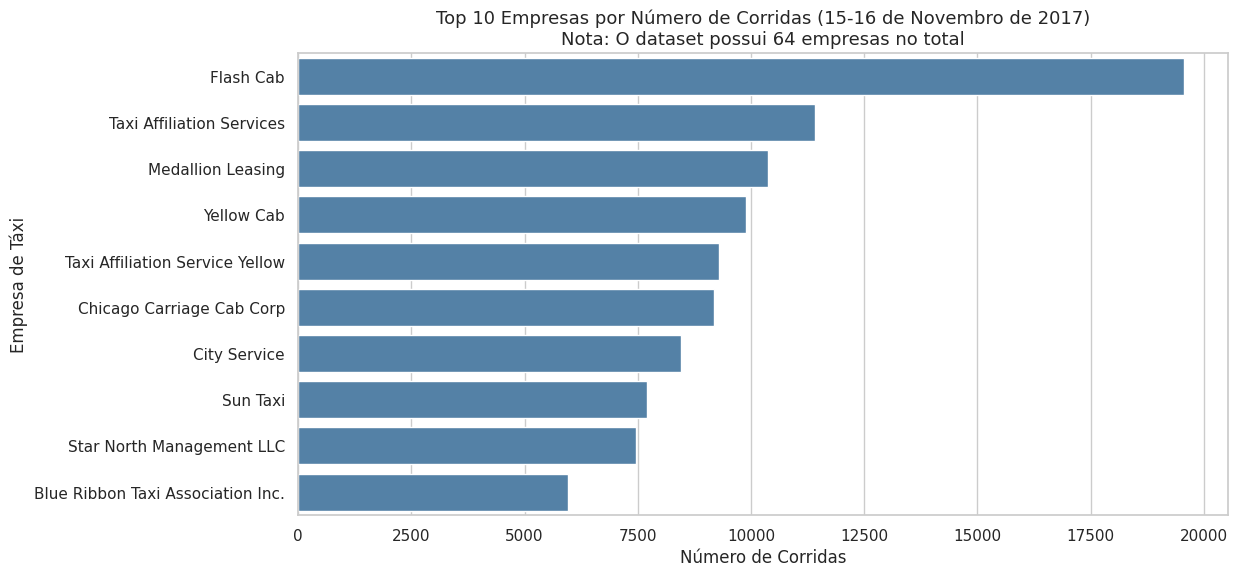

In [8]:
# 1. Identificar os 10 principais bairros em termos de destino
top10_dropoffs = dropoffs.sort_values(by='average_trips', ascending=False).head(10)
print("=== Top 10 Bairros de Destino ===")
print(top10_dropoffs)

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid")

# Gráfico 1: Empresas de Táxi e Número de Corridas (Top 10 Empresas)
plt.figure(figsize=(12, 6))
top_companies = companies.sort_values(by='trips_amount', ascending=False).head(10)

# Cor única, pois o comprimento da barra já indica o valor
sns.barplot(data=top_companies, x='trips_amount', y='company_name', color='steelblue')
plt.title('Top 10 Empresas por Número de Corridas (15-16 de Novembro de 2017)\nNota: O dataset possui 64 empresas no total', fontsize=13)
plt.xlabel('Número de Corridas', fontsize=12)
plt.ylabel('Empresa de Táxi', fontsize=12)
plt.show()

**Conclusão do gráfico: empresas de táxi e número de corridas**

A **Flash Cab** lidera com clareza, com 19.558 corridas, cerca de 1,7 vez a segunda colocada (Taxi Affiliation Services, 11.422). Da segunda à quinta posição os valores são próximos (11.422 a 9.299), e a distância para a líder é bem maior que a diferença entre elas.

Como os dados cobrem só dois dias, mostram à Zuber que o mercado é concentrado em poucas empresas grandes. Não permitem concluir sobre sazonalidade, dias da semana ou tendências ao longo do tempo.

<div class="alert alert-block alert-warning">
Sua conclusão sobre o gráfico das empresas melhorou bastante. Os números batem com o gráfico, e você explica bem o que dois dias de dados podem e não podem dizer à Zuber. Um ponto opcional: você diz que o mercado é 'concentrado em poucas empresas grandes'. Sua seção de SQL mostra que as empresas 'Other' concentram cerca de 77% das corridas de novembro, e você descreve esse mercado como fragmentado. O gráfico mostra apenas as 10 principais de 64 empresas. Uma redação como 'a Flash Cab lidera com clareza, mas o top 10 não mostra a fatia do mercado como um todo' manteria as duas conclusões consistentes.
</div>

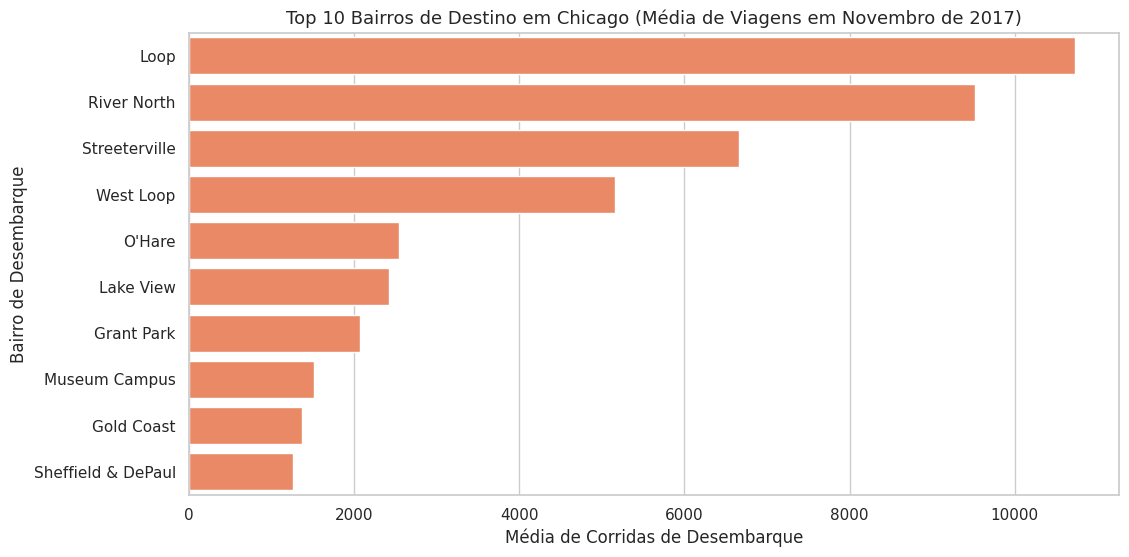

In [5]:
# Gráfico 2: Top 10 Bairros por Média de Corridas de Desembarque
plt.figure(figsize=(12, 6))
sns.barplot(data=top10_dropoffs, x='average_trips', y='dropoff_location_name', color='coral')
plt.title('Top 10 Bairros de Destino em Chicago (Média de Viagens em Novembro de 2017)', fontsize=13)
plt.xlabel('Média de Corridas de Desembarque', fontsize=12)
plt.ylabel('Bairro de Desembarque', fontsize=12)
plt.show()

**Conclusão do gráfico: bairros de destino**

Os bairros Loop (10,7 mil), River North (9,5 mil) e Streeterville (cerca de 6,6 mil) lideram o volume de desembarques, provavelmente por representarem o centro financeiro, hoteleiro e comercial de Chicago.

O bairro West Loop é o 4º colocado (5,2 mil), e observa-se uma queda acentuada até o aeroporto O'Hare, na 5ª posição (2,5 mil).

A presença marcante do Loop e de O'Hare entre os principais destinos justifica a análise focada na rota entre o centro e o aeroporto para o teste de hipótese.

<div class="alert alert-block alert-success">
Sua interpretação do gráfico de bairros está correta. Os valores que você cita correspondem à tabela e ao gráfico. 'Provavelmente' separa o que os dados mostram de uma explicação plausível. Você também destaca a queda acentuada antes de O'Hare, em quinto lugar. Conectar Loop e O'Hare ao teste de hipótese que vem a seguir foi um ótimo toque.
</div>

# Passo 3: Consultas SQL para Construção do Dataset de Viagens Loop -> O'Hare

Para gerar o dataset de análise da rota entre o Loop e o Aeroporto O'Hare nos sábados, executamos as seguintes consultas SQL no banco de dados da plataforma:

# 1. Identificar os IDs dos bairros Loop e O'Hare
```sql
SELECT
    neighborhood_id,
    name
FROM
    neighborhoods
WHERE
    name LIKE 'Loop' OR name LIKE 'O''Hare';
```

# 2. Classificar as condições climáticas por hora (Good vs. Bad)
```sql
SELECT
    ts,
    CASE
        WHEN description LIKE '%rain%' OR description LIKE '%storm%' THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions
FROM
    weather_records;
```

# 3. Unir (JOIN) as corridas de sábado com os registros climáticos
Utilizamos um `INNER JOIN` entre a tabela `trips` e a tabela `weather_records` usando a hora do início da viagem (`start_ts = ts`). A junção interna garante que apenas as viagens que possuem registro correspondente de clima no banco de dados sejam mantidas na análise:

```sql
SELECT
    t.start_ts,
    CASE
        WHEN w.description LIKE '%rain%' OR w.description LIKE '%storm%' THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions,
    t.duration_seconds
FROM
    trips t
INNER JOIN
    neighborhoods n_start ON t.pickup_location_id = n_start.neighborhood_id
INNER JOIN
    neighborhoods n_end ON t.dropoff_location_id = n_end.neighborhood_id
INNER JOIN
    weather_records w ON w.ts = t.start_ts
WHERE
    n_start.name = 'Loop'
    AND n_end.name = 'O''Hare'
    AND EXTRACT(DOW FROM t.start_ts) = 6 -- Filtra apenas os Sábados (DOW = 6)
ORDER BY
    t.trip_id;
```

<div class="alert alert-block alert-warning">
Suas consultas do Passo 3 estão corretas. A primeira consulta obtém os IDs de Loop e O'Hare. A segunda usa `CASE` com `LIKE '%rain%' OR LIKE '%storm%'` para construir `weather_conditions`. A terceira faz o join entre `trips` e `weather_records` pelo horário de início, e `EXTRACT(DOW ...) = 6` isola corretamente os sábados. Sua explicação sobre o `INNER JOIN` está certa. Duas ideias opcionais: (1) Como você já tem os IDs (Loop = 50, O'Hare = 63), você pode filtrar com `t.pickup_location_id = 50 AND t.dropoff_location_id = 63`. Isso elimina os dois joins extras com `neighborhoods`. Na primeira consulta, `=` também é mais claro do que `LIKE` para correspondências exatas de nome. (2) Cada título com `#` faz com que os subpassos fiquem do mesmo tamanho que o título da seção. Usar `###` ou texto em negrito daria uma hierarquia mais clara.
</div>

In [6]:

# Importar os dados de viagens do Loop para O'Hare nos sábados
trips_ohare = pd.read_csv('/datasets/project_sql_result_07.csv')

# Estudar a estrutura dos dados
print("=== Informações do dataset de viagens Loop -> O'Hare ===")
print(trips_ohare.info())
print(trips_ohare.head())

# Separar os dados entre dias bons (Good) e dias chuvosos/ruins (Bad)
good_weather_duration = trips_ohare[trips_ohare['weather_conditions'] == 'Good']['duration_seconds']
bad_weather_duration = trips_ohare[trips_ohare['weather_conditions'] == 'Bad']['duration_seconds']


=== Informações do dataset de viagens Loop -> O'Hare ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB
None
              start_ts weather_conditions  duration_seconds
0  2017-11-25 16:00:00               Good            2410.0
1  2017-11-25 14:00:00               Good            1920.0
2  2017-11-25 12:00:00               Good            1543.0
3  2017-11-04 10:00:00               Good            2512.0
4  2017-11-11 07:00:00               Good            1440.0


# Justificativa da Escolha do Teste Estatístico e Parâmetros

Para testar a hipótese sobre a variação na duração das viagens do Loop até o Aeroporto O'Hare aos sábados, a escolha da metodologia baseou-se nos seguintes aspectos:

1. **Amostras Independentes e Comparação de Médias:** 
   Analisamos dois grupos distintos e não correlacionados de corridas (uma amostra de viagens sob tempo bom e outra sob tempo ruim). Como o objetivo é verificar se a duração média do trajeto muda conforme a condição climática, o **Teste t de Student para duas amostras independentes** é o teste paramétrico ideal para comparar as médias dessas populações.

2. **Verificação de Igualdade de Variâncias (Teste de Levene):**
   O teste t assume, por padrão, que as variâncias dos dois grupos são iguais (homocedasticidade). O **Teste de Levene** foi aplicado previamente para avaliar essa suposição. Se o valor p de Levene for maior que $\alpha$, mantemos `equal_var=True`; caso contrário, ajusta-se para `equal_var=False` (Teste t de Welch), garantindo a precisão do teste sem violar suas premissas.

3. **Nível de Significância ($\alpha = 0{,}05$):**
   Adotou-se o nível padrão de 5%. Esse valor estabelece um *trade-off* equilibrado entre o risco de cometer um **Erro do Tipo I** (falso positivo, ou seja, concluir que o clima altera o tempo de viagem quando na verdade não altera) e um **Erro do Tipo II** (falso negativo, ou seja, deixar de detectar uma diferença real existente).

4. **Formulação das Hipóteses:**
   - **$H_0$ (Hipótese Nula):** A duração média das corridas do Loop para O'Hare nos sábados chuvosos É IGUAL à duração nos sábados de tempo bom ($\mu_{\text{Good}} = \mu_{\text{Bad}}$).
   - **$H_1$ (Hipótese Alternativa):** A duração média das corridas do Loop para O'Hare nos sábados chuvosos É DIFERENTE da duração nos sábados de tempo bom ($\mu_{\text{Good}} \neq \mu_{\text{Bad}}$).

<div class="alert alert-block alert-success">
Sua justificativa está clara e bem organizada. Você explica por que os dois grupos são amostras independentes e por que comparar médias se adequa à pergunta. Você explica para que serve o teste de Levene e como ele define a escolha entre as versões Student e Welch do teste t. Você também explica o alfa = 0,05 por meio do trade-off entre erro Tipo I e erro Tipo II. A hipótese alternativa bilateral corresponde à pergunta sobre se a duração 'muda'.
</div>

In [7]:
# Nível de significância (alpha)
alpha = 0.05

# Teste de Levene para verificar igualdade de variâncias
levene_stat, levene_pvalue = stats.levene(good_weather_duration, bad_weather_duration)
equal_variances = levene_pvalue > alpha

# Aplicação do Teste t de Student para duas amostras independentes
results = stats.ttest_ind(good_weather_duration, bad_weather_duration, equal_var=equal_variances)

# Cálculo do impacto prático em minutos
diff_seconds = bad_weather_duration.mean() - good_weather_duration.mean()
diff_minutes = diff_seconds / 60

# Exibição dos resultados numéricos e estatísticos
print("=== Métricas das Amostras ===")
print(f"Tamanho da amostra (Tempo Bom): {len(good_weather_duration)} corridas")
print(f"Tamanho da amostra (Tempo Ruim): {len(bad_weather_duration)} corridas")
print(f"Média de duração (Tempo Bom): {good_weather_duration.mean():.2f} segundos (~{good_weather_duration.mean()/60:.1f} minutos)")
print(f"Média de duração (Tempo Ruim): {bad_weather_duration.mean():.2f} segundos (~{bad_weather_duration.mean()/60:.1f} minutos)")
print(f"Diferença prática média: +{diff_seconds:.2f} segundos (~{diff_minutes:.1f} minutos a mais na chuva)")

print("\n=== Resultados dos Testes Estatísticos ===")
print(f"Teste de Levene (p-valor): {levene_pvalue:.4f} -> Variâncias iguais? {equal_variances}")
print(f"Teste t de Student (p-valor): {results.pvalue}")

if results.pvalue < alpha:
    print("\nResultado: Rejeitamos a hipótese nula.")
    print("Conclusão: Há evidências estatísticas suficientes para afirmar que a duração média das corridas do Loop para o Aeroporto O'Hare altera-se em sábados chuvosos.")
else:
    print("\nResultado: Não podemos rejeitar a hipótese nula.")
    print("Conclusão: Não há evidência estatística suficiente de diferença nas durações médias.")


=== Métricas das Amostras ===
Tamanho da amostra (Tempo Bom): 888 corridas
Tamanho da amostra (Tempo Ruim): 180 corridas
Média de duração (Tempo Bom): 1999.68 segundos (~33.3 minutos)
Média de duração (Tempo Ruim): 2427.21 segundos (~40.5 minutos)
Diferença prática média: +427.53 segundos (~7.1 minutos a mais na chuva)

=== Resultados dos Testes Estatísticos ===
Teste de Levene (p-valor): 0.5332 -> Variâncias iguais? True
Teste t de Student (p-valor): 6.517970327099473e-12

Resultado: Rejeitamos a hipótese nula.
Conclusão: Há evidências estatísticas suficientes para afirmar que a duração média das corridas do Loop para o Aeroporto O'Hare altera-se em sábados chuvosos.


<div class="alert alert-block alert-success">
Seu código de teste está correto e bem apresentado. Você usa o p-valor de Levene (0.5332) para definir `equal_var` em `ttest_ind`. Você também imprime os tamanhos das amostras (888 vs. 180) e as durações médias (cerca de 33,3 vs. 40,5 minutos), de modo que o leitor consiga ver o tamanho prático da diferença. O p-valor (cerca de 6.5e-12) está muito abaixo de alfa, então rejeitar a hipótese nula é a decisão correta, e sua conclusão está redigida de forma adequada.
</div>

## Conclusão geral do projeto

- **Empresas de táxi:** a Flash Cab lidera com clareza, com cerca de 19,6 mil corridas em 15 e 16 de novembro de 2017. Taxi Affiliation Services (cerca de 11,4 mil), Medallion Leasing (cerca de 10,4 mil) e Yellow Cab (cerca de 9,9 mil) formam um grupo mais próximo logo atrás.
- **Bairros:** Loop, River North e Streeterville estão entre os principais destinos, provavelmente por concentrarem áreas comerciais e turísticas (os dados não medem o motivo).
- **Clima:** rejeitamos a hipótese nula (p = 6,52 × 10⁻¹²). Chuva ou tempestade está associada a viagens mais longas do Loop ao Aeroporto O'Hare: cerca de 33 minutos em sábados de tempo bom contra cerca de 40 em sábados ruins, uma diferença de cerca de 7 minutos.

<div class="alert alert-block alert-success">
Seu resumo final une as três partes do projeto, e cada conclusão agora tem seu próprio marcador. Você separa a liderança clara da Flash Cab do grupo mais próximo logo atrás dela. Você qualifica a explicação sobre os bairros com 'provavelmente'. Você também usa 'está associada a viagens mais longas' em vez de uma afirmação causal, e os números correspondem aos seus resultados.
</div>